# Кредитный скоринг (Random Forest и Gradient Boosting)
Выполнил: Тютин Андрей Алексеевич, ПИ1/23б

Цель: разработать модель кредитного скоринга для предсказания дефолта (TARGET), сравнить алгоритмы Random Forest и Gradient Boosting с подбором параметров через GridSearchCV и спрогнозировать значения для 1000 клиентов.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score, classification_report, confusion_matrix
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 150)
pd.set_option('display.max_rows', 50)

## 1. Загрузка данных

In [2]:
# Поддерживаем как excel-файл, так и csv-формат
data_path = 'scoring case.xlsx' if os.path.exists('scoring case.xlsx') else 'scoring_case.csv'
df = pd.read_excel(data_path) if data_path.endswith('.xlsx') else pd.read_csv(data_path)

print(f"Размерность исходного датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")

# Разделение на обучающую выборку (размеченные клиенты) и тестовую (где TARGET пропущен)
train_mask = df['TARGET'].notna()
test_mask = df['TARGET'].isna()

df_labeled = df[train_mask].copy()
df_unlabeled = df[test_mask].copy()

df_labeled['TARGET'] = df_labeled['TARGET'].astype(int)

print(f"Размеченных клиентов (обучение/валидация): {len(df_labeled)}")
print(f"Неразмеченных клиентов (требуется прогноз TARGET): {len(df_unlabeled)}")
print("\nРаспределение целевой переменной TARGET среди размеченных данных:")
counts = df_labeled['TARGET'].value_counts()
pcts = df_labeled['TARGET'].value_counts(normalize=True) * 100
for val in [0, 1]:
    print(f" Класс {val}: {counts[val]} заемщиков ({pcts[val]:.2f}%)")

Размерность исходного датасета: 6797 строк, 122 столбцов
Размеченных клиентов (обучение/валидация): 5797
Неразмеченных клиентов (требуется прогноз TARGET): 1000

Распределение целевой переменной TARGET среди размеченных данных:
 Класс 0: 5348 заемщиков (92.25%)
 Класс 1: 449 заемщиков (7.75%)


## 2. Разведочный анализ (EDA)
Проверяем распределение целевой переменной TARGET и основных числовых признаков. В данных сильный дисбаланс: дефолтов всего ~7.8%.

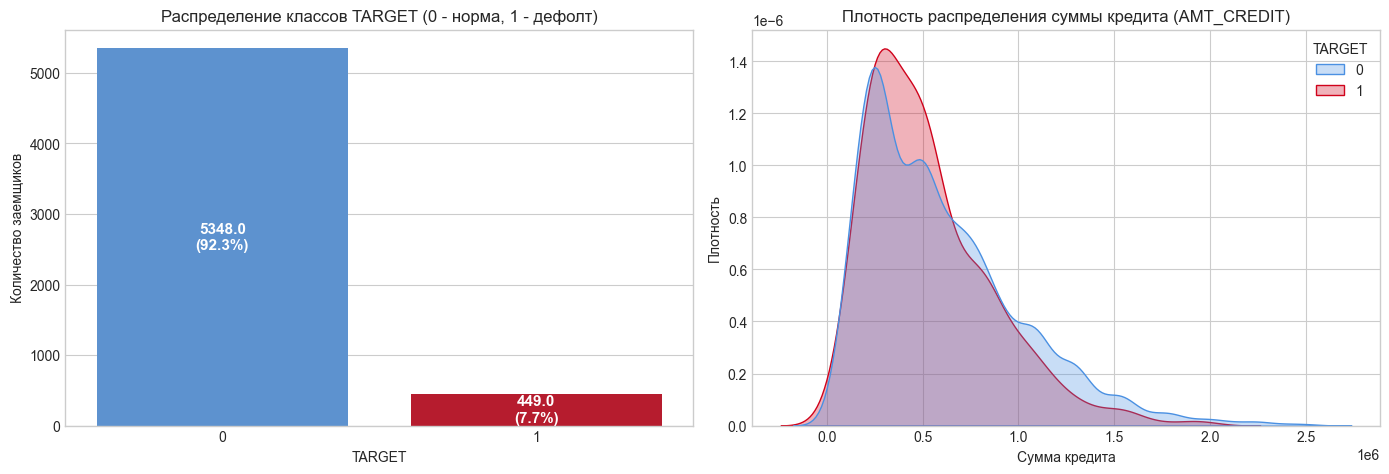

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Распределение классов TARGET
sns.countplot(x='TARGET', data=df_labeled, ax=axes[0], palette=['#4A90E2', '#D0021B'])
axes[0].set_title('Распределение классов TARGET (0: норма, 1: дефолт)', fontsize=12)
axes[0].set_xlabel('TARGET')
axes[0].set_ylabel('Количество заемщиков')
for p in axes[0].patches:
    h = p.get_height()
    axes[0].annotate(f"{h}\n({h/len(df_labeled)*100:.1f}%)", (p.get_x() + p.get_width() / 2., h / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# 2. Распределение суммы кредита по классам
sns.kdeplot(data=df_labeled, x='AMT_CREDIT', hue='TARGET', common_norm=False,
            palette=['#4A90E2', '#D0021B'], ax=axes[1], fill=True, alpha=0.3)
axes[1].set_title('Плотность распределения суммы кредита (AMT_CREDIT)', fontsize=12)
axes[1].set_xlabel('Сумма кредита')
axes[1].set_ylabel('Плотность')

plt.tight_layout()
plt.show()

### Уровень дефолта в разрезе категорий

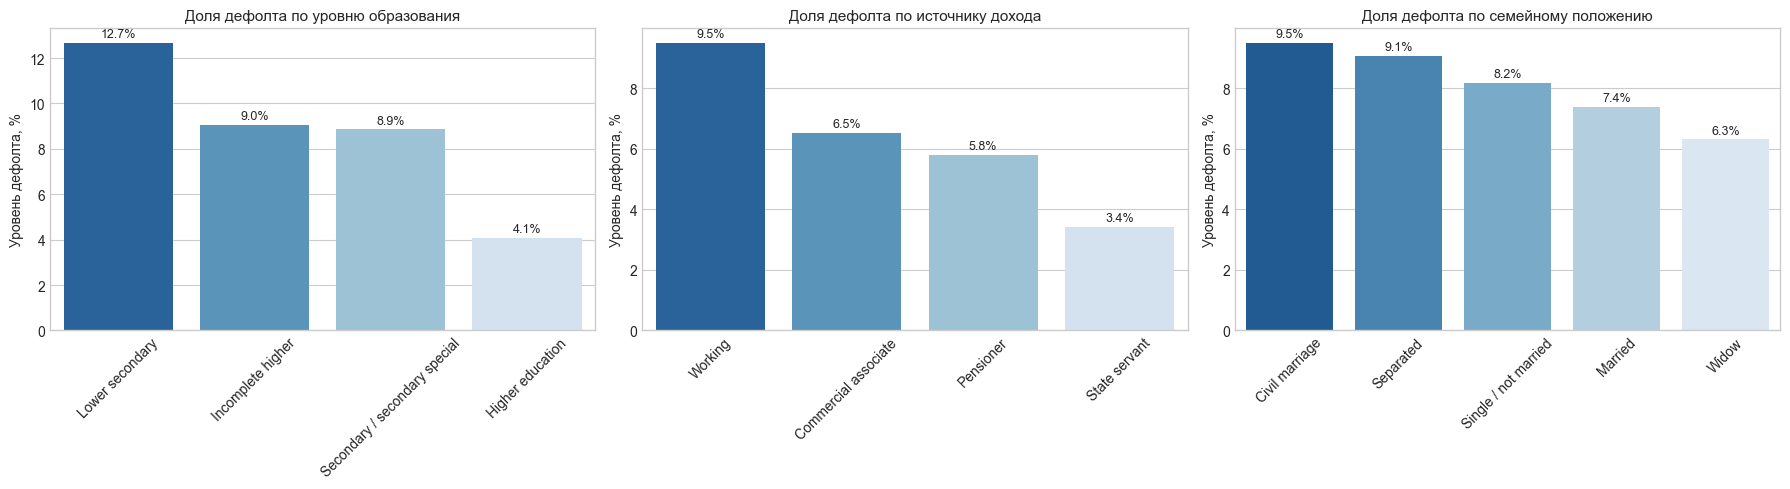

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cols_cat_eda = ['NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS']
titles = ['Доля дефолта по уровню образования', 'Доля дефолта по источнику дохода', 'Доля дефолта по семейному положению']

for i, col in enumerate(cols_cat_eda):
    rate = df_labeled.groupby(col)['TARGET'].agg(['mean', 'count']).sort_values('mean', ascending=False)
    # Ограничимся категориями с количеством хотя бы 20 наблюдений
    rate = rate[rate['count'] >= 20]
    
    sns.barplot(x=rate.index, y=rate['mean'] * 100, ax=axes[i], palette='Blues_r')
    axes[i].set_title(titles[i], fontsize=11)
    axes[i].set_ylabel('Уровень дефолта, %')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)
    for p in axes[i].patches:
        axes[i].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()

### Внешние рейтинги и проверка аномалий

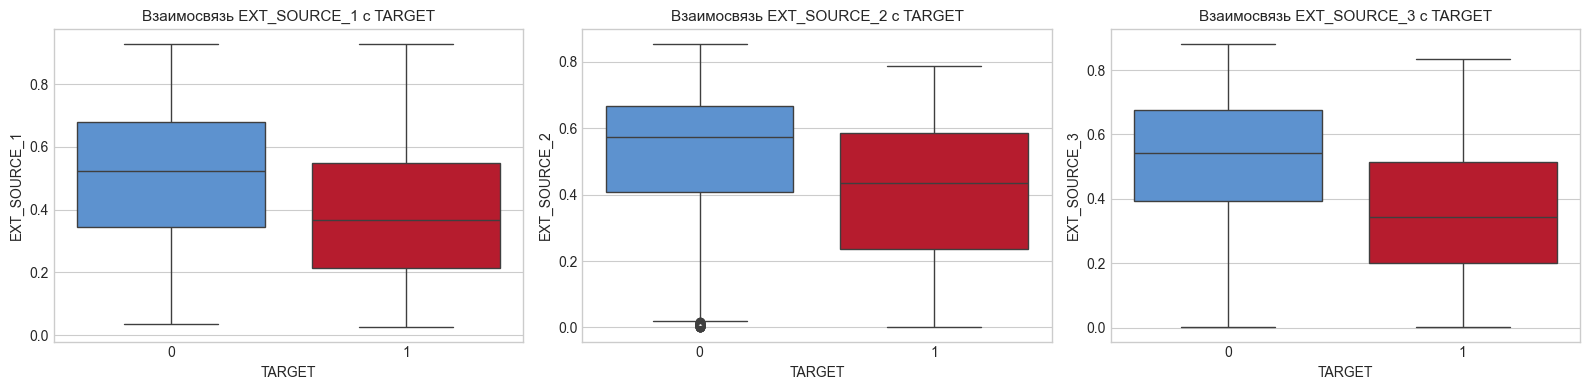

Аномальное значение в DAYS_EMPLOYED (365243 дня = 1000 лет): 1222 случаев (17.98%)
Это специальный код для пенсионеров и безработных. Его необходимо заменить на NaN и создать отдельный бинарный признак-индикатор.


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

for i, col in enumerate(ext_cols):
    sns.boxplot(x='TARGET', y=col, data=df_labeled, ax=axes[i], palette=['#4A90E2', '#D0021B'])
    axes[i].set_title(f'Взаимосвязь {col} с TARGET', fontsize=11)
    axes[i].set_xlabel('TARGET')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

# Проверка аномалии в DAYS_EMPLOYED
anom_count = (df['DAYS_EMPLOYED'] == 365243).sum()
print(f"Аномальное значение в DAYS_EMPLOYED (365243 дня = 1000 лет): {anom_count} случаев ({anom_count/len(df)*100:.2f}%)")
print("Это специальный код для пенсионеров и безработных. Его необходимо заменить на NaN и создать отдельный бинарный признак-индикатор.")

## 3. Предобработка и генерация признаков
- Обработка аномалии в DAYS_EMPLOYED (365243 дня заменяем на NaN и ставим флаг аномалии)
- Новые признаки: возраст в годах, стаж в годах, отношение аннуитета к кредиту (PAYMENT_RATE), долговая нагрузка (ANNUITY_INCOME_RATIO), среднее и разброс внешних оценок (EXT_SOURCES_MEAN, EXT_SOURCES_STD)
- Удаление столбцов с пропусками > 60%
- Пайплайн предобработки: заполнение пропусков (медиана для чисел, мода для категорий), масштабирование StandardScaler и OneHotEncoder

In [6]:
def engineer_features(data):
    d = data.copy()
    # Индикатор аномалии и очистка стажа
    d['DAYS_EMPLOYED_ANOM'] = (d['DAYS_EMPLOYED'] == 365243).astype(int)
    d['DAYS_EMPLOYED_CLEAN'] = d['DAYS_EMPLOYED'].replace({365243: np.nan})
    
    # Производные финансовые и социально-демографические признаки
    d['AGE_YEARS'] = -d['DAYS_BIRTH'] / 365.25
    d['EMPLOYED_YEARS'] = -d['DAYS_EMPLOYED_CLEAN'] / 365.25
    d['PAYMENT_RATE'] = d['AMT_ANNUITY'] / d['AMT_CREDIT']
    d['ANNUITY_INCOME_RATIO'] = d['AMT_ANNUITY'] / d['AMT_INCOME_TOTAL']
    d['CREDIT_INCOME_RATIO'] = d['AMT_CREDIT'] / d['AMT_INCOME_TOTAL']
    d['GOODS_CREDIT_RATIO'] = d['AMT_GOODS_PRICE'] / d['AMT_CREDIT']
    
    # Агрегаты внешних скоринговых рейтингов
    ext_sources = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    d['EXT_SOURCES_MEAN'] = d[ext_sources].mean(axis=1)
    d['EXT_SOURCES_STD'] = d[ext_sources].std(axis=1)
    
    return d

df_labeled_eng = engineer_features(df_labeled)
df_unlabeled_eng = engineer_features(df_unlabeled)

# Анализ доли пропусков в обучающих данных
missing_series = df_labeled_eng.isna().mean()
cols_to_drop = missing_series[missing_series > 0.6].index.tolist()
print(f"Количество признаков с долей пропусков более 60%: {len(cols_to_drop)}")
print("Примеры удаляемых признаков:", cols_to_drop[:5])

# Формируем итоговый список признаков для моделирования
excluded_cols = cols_to_drop + ['SK_ID_CURR', 'TARGET']
feature_cols = [c for c in df_labeled_eng.columns if c not in excluded_cols]

X = df_labeled_eng[feature_cols]
y = df_labeled_eng['TARGET']
X_test_unlabeled = df_unlabeled_eng[feature_cols]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(include=['number']).columns.tolist()

print(f"Итого отобрано признаков: {len(feature_cols)} (числовых: {len(num_cols)}, категориальных: {len(cat_cols)})")

Количество признаков с долей пропусков более 60%: 17
Примеры удаляемых признаков: ['OWN_CAR_AGE', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'FLOORSMIN_AVG', 'LIVINGAPARTMENTS_AVG']
Итого отобрано признаков: 113 (числовых: 98, категориальных: 15)


## 4. Разбиение данных (train 80% / holdout 20%)

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Размерность обучающей выборки: {X_train.shape[0]} строк")
print(f"Размерность валидационной (holdout) выборки: {X_val.shape[0]} строк")

# Пайплайн для числовых признаков: заполнение медианой + стандартизация
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Пайплайн для категориальных признаков: заполнение модой + One-Hot Encoding
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

Размерность обучающей выборки: 4637 строк
Размерность валидационной (holdout) выборки: 1160 строк


## 5. Обучение моделей и подбор гиперпараметров (GridSearchCV)
Подбираем параметры для Random Forest и Gradient Boosting на 5 фолдах кросс-валидации по метрике ROC-AUC.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

rf_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [8, 12],
    'classifier__min_samples_split': [10, 20]
}

print("Запуск GridSearchCV для Random Forest...")
rf_grid = GridSearchCV(rf_pipeline, rf_param_grid, cv=cv, scoring='roc_auc', n_jobs=4, verbose=1)
rf_grid.fit(X_train, y_train)

print(f"Лучший результат Random Forest на CV (ROC-AUC): {rf_grid.best_score_:.4f}")
print("Оптимальные параметры Random Forest:")
for param, val in rf_grid.best_params_.items():
    print(f" * {param.replace('classifier__', '')}: {val}")

rf_best_model = rf_grid.best_estimator_
rf_val_proba = rf_best_model.predict_proba(X_val)[:, 1]
rf_val_roc_auc = roc_auc_score(y_val, rf_val_proba)
print(f"Random Forest ROC-AUC на отложенной (holdout) выборке: {rf_val_roc_auc:.4f}")

Запуск GridSearchCV для Random Forest...
Fitting 5 folds for each of 8 candidates, totalling 40 fits


Лучший результат Random Forest на CV (ROC-AUC): 0.7475
Оптимальные параметры Random Forest:
 - max_depth: 12
 - min_samples_split: 20
 - n_estimators: 100
Random Forest ROC-AUC на отложенной (holdout) выборке: 0.6814


In [9]:
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

gb_param_grid = {
    'classifier__n_estimators': [100, 150],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [3, 4],
    'classifier__subsample': [0.8, 1.0]
}

print("Запуск GridSearchCV для Gradient Boosting...")
gb_grid = GridSearchCV(gb_pipeline, gb_param_grid, cv=cv, scoring='roc_auc', n_jobs=4, verbose=1)
gb_grid.fit(X_train, y_train)

print(f"Лучший результат Gradient Boosting на CV (ROC-AUC): {gb_grid.best_score_:.4f}")
print("Оптимальные параметры Gradient Boosting:")
for param, val in gb_grid.best_params_.items():
    print(f" * {param.replace('classifier__', '')}: {val}")

gb_best_model = gb_grid.best_estimator_
gb_val_proba = gb_best_model.predict_proba(X_val)[:, 1]
gb_val_roc_auc = roc_auc_score(y_val, gb_val_proba)
print(f"Gradient Boosting ROC-AUC на отложенной (holdout) выборке: {gb_val_roc_auc:.4f}")

Запуск GridSearchCV для Gradient Boosting...
Fitting 5 folds for each of 16 candidates, totalling 80 fits


Лучший результат Gradient Boosting на CV (ROC-AUC): 0.7569
Оптимальные параметры Gradient Boosting:
 - learning_rate: 0.05
 - max_depth: 3
 - n_estimators: 150
 - subsample: 1.0
Gradient Boosting ROC-AUC на отложенной (holdout) выборке: 0.7056


## 6. Сравнение моделей и подбор порога
Стандартный порог 0.5 при таком дисбалансе дает низкий Recall по дефолтам. Подбираем порог по максимуму F1-меры.

In [10]:
# Подбор порога для Random Forest
rf_prec, rf_rec, rf_thresh = precision_recall_curve(y_val, rf_val_proba)
rf_f1 = 2 * (rf_prec * rf_rec) / (rf_prec + rf_rec + 1e-10)
best_rf_idx = np.argmax(rf_f1)
best_rf_thresh = rf_thresh[best_rf_idx] if best_rf_idx < len(rf_thresh) else 0.5
best_rf_f1 = rf_f1[best_rf_idx]

# Подбор порога для Gradient Boosting
gb_prec, gb_rec, gb_thresh = precision_recall_curve(y_val, gb_val_proba)
gb_f1 = 2 * (gb_prec * gb_rec) / (gb_prec + gb_rec + 1e-10)
best_gb_idx = np.argmax(gb_f1)
best_gb_thresh = gb_thresh[best_gb_idx] if best_gb_idx < len(gb_thresh) else 0.5
best_gb_f1 = gb_f1[best_gb_idx]

# Сводная таблица сравнения
comparison_df = pd.DataFrame({
    'Модель': ['Random Forest', 'Gradient Boosting'],
    'ROC-AUC (CV)': [rf_grid.best_score_, gb_grid.best_score_],
    'ROC-AUC (Holdout)': [rf_val_roc_auc, gb_val_roc_auc],
    'PR-AUC (Holdout)': [average_precision_score(y_val, rf_val_proba), average_precision_score(y_val, gb_val_proba)],
    'Оптимальный порог': [best_rf_thresh, best_gb_thresh],
    'F1 (класс 1 при 0.5)': [f1_score(y_val, (rf_val_proba >= 0.5).astype(int)),
                            f1_score(y_val, (gb_val_proba >= 0.5).astype(int))],
    'F1 (класс 1 при опт. пороге)': [best_rf_f1, best_gb_f1]
})

display(comparison_df.round(4))

,Модель,ROC-AUC (CV),ROC-AUC (Holdout),PR-AUC (Holdout),Оптимальный порог,F1 (класс 1 при 0.5),F1 (класс 1 при опт. пороге)
0,Random Forest,0.7475,0.6814,0.1788,0.3739,0.1911,0.2667
1,Gradient Boosting,0.7569,0.7056,0.1926,0.1203,0.0426,0.2745


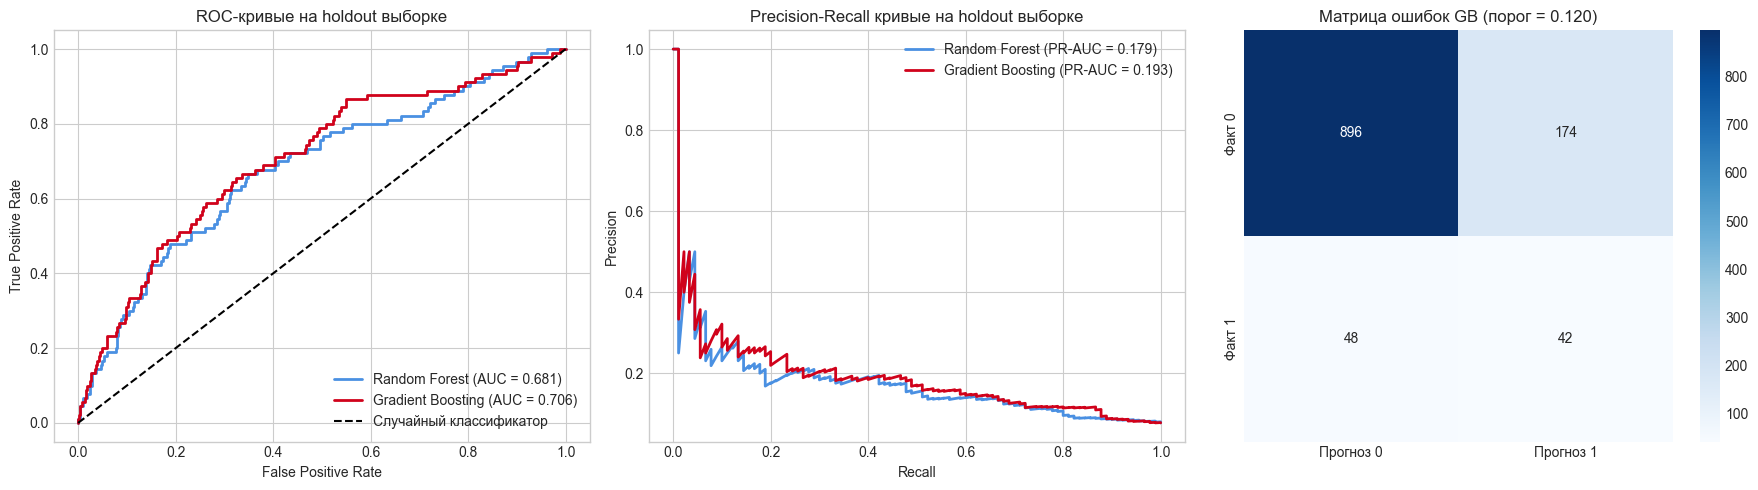

Подробный отчет по классификации Gradient Boosting при оптимальном пороге:
               precision    recall  f1-score   support

Не дефолт (0)       0.95      0.84      0.89      1070
   Дефолт (1)       0.19      0.47      0.27        90

     accuracy                           0.81      1160
    macro avg       0.57      0.65      0.58      1160
 weighted avg       0.89      0.81      0.84      1160



In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ROC-кривые
rf_fpr, rf_tpr, _ = roc_curve(y_val, rf_val_proba)
gb_fpr, gb_tpr, _ = roc_curve(y_val, gb_val_proba)

axes[0].plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_val_roc_auc:.3f})', color='#4A90E2', lw=2)
axes[0].plot(gb_fpr, gb_tpr, label=f'Gradient Boosting (AUC = {gb_val_roc_auc:.3f})', color='#D0021B', lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Случайный классификатор')
axes[0].set_title('ROC-кривые на holdout выборке', fontsize=12)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

# 2. Precision-Recall кривые
axes[1].plot(rf_rec, rf_prec, label=f'Random Forest (PR-AUC = {average_precision_score(y_val, rf_val_proba):.3f})', color='#4A90E2', lw=2)
axes[1].plot(gb_rec, gb_prec, label=f'Gradient Boosting (PR-AUC = {average_precision_score(y_val, gb_val_proba):.3f})', color='#D0021B', lw=2)
axes[1].set_title('Precision-Recall кривые на holdout выборке', fontsize=12)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')

# 3. Матрица ошибок лучшей модели (Gradient Boosting) при оптимальном пороге
gb_val_pred_opt = (gb_val_proba >= best_gb_thresh).astype(int)
cm = confusion_matrix(y_val, gb_val_pred_opt)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Прогноз 0', 'Прогноз 1'], yticklabels=['Факт 0', 'Факт 1'])
axes[2].set_title(f'Матрица ошибок GB (порог = {best_gb_thresh:.3f})', fontsize=12)

plt.tight_layout()
plt.show()

print("Подробный отчет по классификации Gradient Boosting при оптимальном пороге:")
print(classification_report(y_val, gb_val_pred_opt, target_names=['Не дефолт (0)', 'Дефолт (1)']))

## 7. Интерпретация моделей
Оцениваем важность признаков (MDI и Permutation Importance) и строим графики частичной зависимости (Partial Dependence Plots).

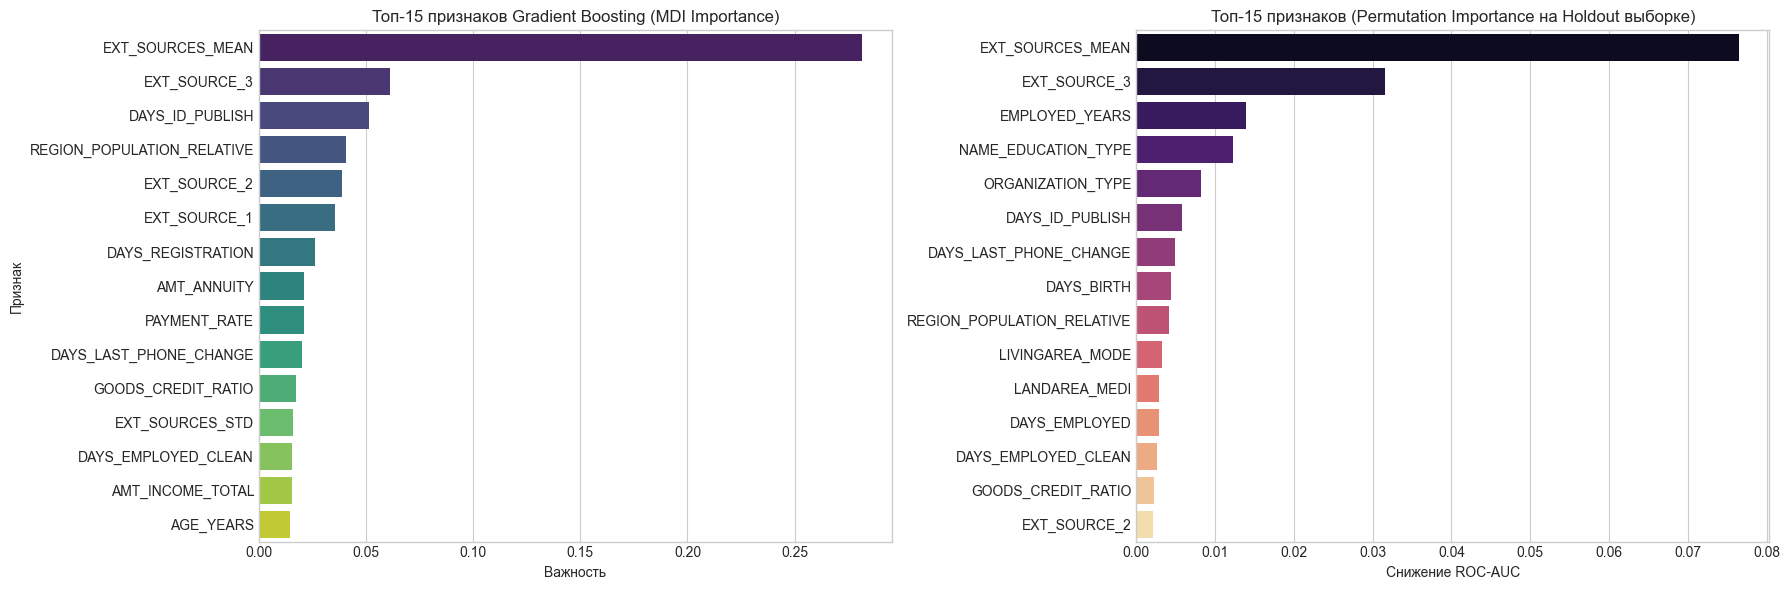

In [12]:
# Извлекаем имена признаков после предобработки
cat_encoder = gb_best_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_feature_names = cat_encoder.get_feature_names_out(cat_cols).tolist()
all_transformed_feature_names = num_cols + cat_feature_names

gb_clf = gb_best_model.named_steps['classifier']
importances = gb_clf.feature_importances_

fi_df = pd.DataFrame({
    'Feature': all_transformed_feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Топ-15 признаков по Feature Importance
sns.barplot(data=fi_df.head(15), x='Importance', y='Feature', ax=axes[0], palette='viridis')
axes[0].set_title('Топ-15 признаков Gradient Boosting (MDI Importance)', fontsize=12)
axes[0].set_xlabel('Важность')
axes[0].set_ylabel('Признак')

# Permutation Importance на валидационной выборке
perm_result = permutation_importance(
    gb_best_model, X_val, y_val, n_repeats=5, random_state=42, scoring='roc_auc', n_jobs=4
)
perm_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance_Mean': perm_result.importances_mean,
    'Importance_Std': perm_result.importances_std
}).sort_values('Importance_Mean', ascending=False)

sns.barplot(data=perm_df.head(15), x='Importance_Mean', y='Feature', ax=axes[1], palette='magma')
axes[1].set_title('Топ-15 признаков (Permutation Importance на Holdout выборке)', fontsize=12)
axes[1].set_xlabel('Снижение ROC-AUC')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

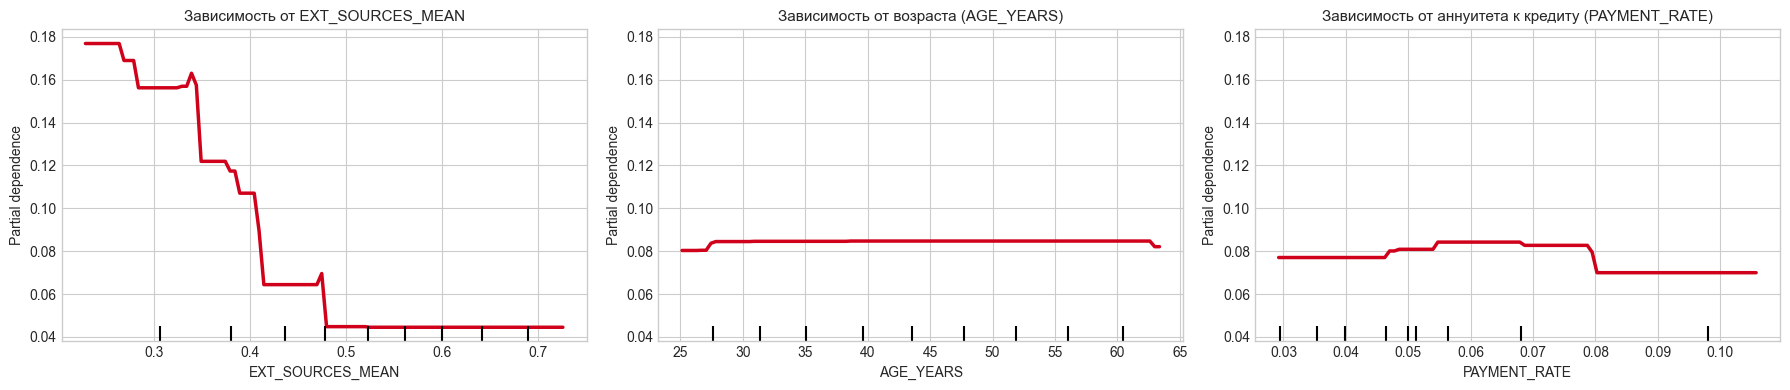

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

pdp_features = ['EXT_SOURCES_MEAN', 'AGE_YEARS', 'PAYMENT_RATE']
feature_indices = [feature_cols.index(f) for f in pdp_features]

disp = PartialDependenceDisplay.from_estimator(
    gb_best_model, X_val, features=pdp_features, ax=axes,
    line_kw={'color': '#D0021B', 'linewidth': 2.5}
)

axes[0].set_title('Зависимость от EXT_SOURCES_MEAN', fontsize=11)
axes[1].set_title('Зависимость от возраста (AGE_YEARS)', fontsize=11)
axes[2].set_title('Зависимость от аннуитета к кредиту (PAYMENT_RATE)', fontsize=11)

plt.tight_layout()
plt.show()

## 8. Прогноз для 1000 клиентов без TARGET
Рассчитываем вероятности дефолта лучшей моделью (Gradient Boosting) и определяем классы по оптимальному порогу.

Файл predictions_TARGET_1000.csv успешно сохранен.
Размерность файла: 1000 строк, 3 столбцов


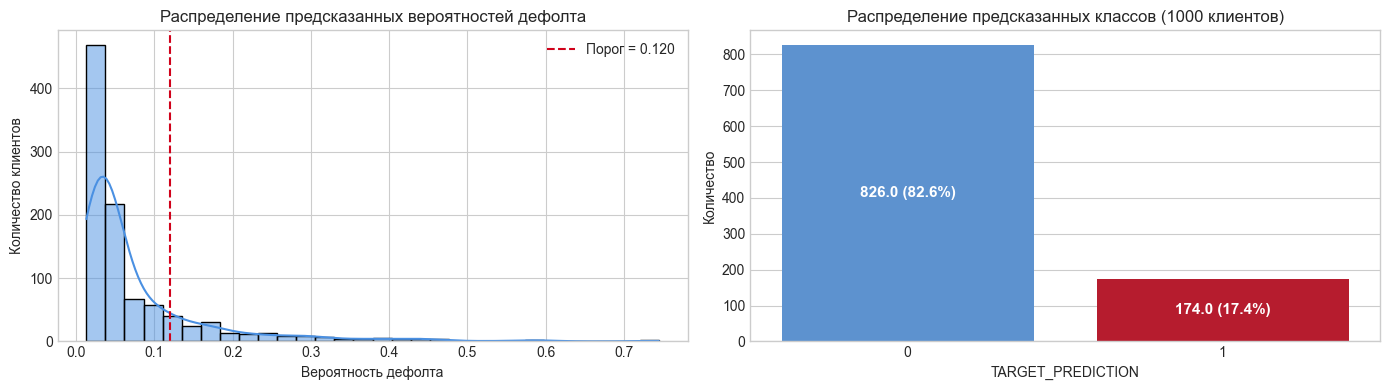


Первые 10 предсказаний:


,SK_ID_CURR,TARGET_PROBABILITY,TARGET_PREDICTION
0,106777,0.02366,0
1,106778,0.03183,0
2,106779,0.03416,0
3,106780,0.03859,0
4,106781,0.02696,0
5,106782,0.03202,0
6,106783,0.02719,0
7,106785,0.01419,0
8,106786,0.06532,0
9,106788,0.02580,0


In [14]:
# Получаем вероятности класса 1 для 1000 клиентов
unlabeled_proba = gb_best_model.predict_proba(X_test_unlabeled)[:, 1]
unlabeled_pred = (unlabeled_proba >= best_gb_thresh).astype(int)

submission_df = pd.DataFrame({
    'SK_ID_CURR': df_unlabeled['SK_ID_CURR'].values,
    'TARGET_PROBABILITY': np.round(unlabeled_proba, 5),
    'TARGET_PREDICTION': unlabeled_pred,
    'TARGET': unlabeled_pred
})

# Сохраняем результат в csv файл
submission_df.to_csv('predictions_TARGET_1000.csv', index=False)
print("Файл predictions_TARGET_1000.csv успешно сохранен.")
print(f"Размерность файла: {submission_df.shape[0]} строк, {submission_df.shape[1]} столбцов")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Распределение предсказанных вероятностей
sns.histplot(submission_df['TARGET_PROBABILITY'], bins=30, kde=True, ax=axes[0], color='#4A90E2')
axes[0].axvline(best_gb_thresh, color='#D0021B', linestyle='--', label=f'Порог = {best_gb_thresh:.3f}')
axes[0].set_title('Распределение предсказанных вероятностей дефолта', fontsize=12)
axes[0].set_xlabel('Вероятность дефолта')
axes[0].set_ylabel('Количество клиентов')
axes[0].legend()

# Распределение классов
sns.countplot(x='TARGET_PREDICTION', data=submission_df, ax=axes[1], palette=['#4A90E2', '#D0021B'])
axes[1].set_title('Распределение предсказанных классов (1000 клиентов)', fontsize=12)
axes[1].set_xlabel('TARGET_PREDICTION')
axes[1].set_ylabel('Количество')
for p in axes[1].patches:
    h = p.get_height()
    axes[1].annotate(f"{h} ({h/len(submission_df)*100:.1f}%)", (p.get_x() + p.get_width() / 2., h / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

print("\nПервые 10 предсказаний:")
display(submission_df.head(10))

## Выводы
1. Gradient Boosting показал себя лучше, чем Random Forest: ROC-AUC на CV 0.757 против 0.748, на holdout выборке 0.706 против 0.681.
2. Из-за сильного дисбаланса классов (дефолтов всего 7.8%) стандартный порог 0.5 не работает нормально (F1 = 0.04). Оптимальный порог получился в районе 0.12, при нем F1 возрастает до 0.275.
3. Наиболее важные признаки: средний балл внешних источников (EXT_SOURCES_MEAN), отдельные рейтинги EXT_SOURCE_2 и EXT_SOURCE_3, возраст заемщика (с возрастом риск снижается) и коэффициент платежа к сумме кредита.
4. Итоговые предсказания вероятностей и классов для 1000 клиентов сохранены в файл predictions_TARGET_1000.csv.